<a href="https://colab.research.google.com/github/Jo-Banana-123/Poker-Game-Logistic-Regression/blob/main/Joanna_Lin_ACM_AI_Tiny_Poker_Challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ACM AI · Tiny Poker Decision Model
Build a small model that takes a game situation and information about an opponent,
then outputs **P(fold), P(call), P(raise)**. There is intentionally no prescribed
model, feature representation, evaluation procedure, or definition of “better.”
Make reasonable choices, state your assumptions, and show evidence for your conclusions.

We care about your investigation and how you direct AI agents as much as the result.
Use an AI coding/reasoning tool of your choice! Keep brief
notes as you work so the final reflection is concrete. You are responsible for checking its suggestions.

The most interesting parts will be reading your thought process. Have fun!

## Enough poker to get started

Each row is an independent, simplified decision while facing an opponent's bet.
All three actions are available: **fold** = give up this hand; **call** = match the bet;
**raise** = increase the bet. You do not need to learn card rules.

The target `action` is a **sampled action from a fictional, noisy policy**.
Predict its behavior; these labels are not optimal poker strategy or evidence of profitability.
The probability of an action describes what the fictional player might choose given the inputs.

| Column | Meaning |
| :--- | :--- |
| `decision_id` | Record identifier |
| `hand_strength` | Approximate strength of the player's hand, 0 (weak) to 1 (strong) |
| `pot_odds` | Cost to call / (current pot + cost to call); larger means a more expensive call |
| `stack_to_pot` | Remaining chips relative to the pot; larger means more room to bet |
| `position` | `early`, `middle`, or `late`; later positions generally have more information |
| `opponent_aggression` | Estimated tendency to bet or raise, 0–1 |
| `opponent_fold_rate` | Estimated tendency to fold when challenged, 0–1 |
| `opponent_bluff_rate` | Estimated tendency to bet with weak hands, 0–1 |
| `recent_actions` | Opponent's actions in earlier situations, oldest to newest, comma-separated; `check` means pass without betting |
| `action` | Target: `fold`, `call`, or `raise` |

All inputs precede the target action. Opponent summaries and history are imperfect observations.
This is synthetic data with some missing observations. The generator below is provided
for reproducibility; you can leave it collapsed. Investigate the generated table rather
than using the generator's action-scoring formula as your predictor.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
ACTIONS = ["fold", "call", "raise"]  # Use this order in your probability output.

In [ ]:
# @title Load the embedded exercise data (no edits needed)
import base64
import gzip
import io

_DATA = """
...
F8TuTskhBAA=
"""
df = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(_DATA))))
print(f"{len(df):,} decisions · {df.shape[1] - 1} input columns")
display(df.head())


1,800 decisions · 9 input columns


,decision_id,hand_strength,pot_odds,stack_to_pot,position,opponent_aggression,opponent_fold_rate,opponent_bluff_rate,recent_actions,action
0,D-000008,0.426436,0.164588,1.244714,middle,0.442266,0.434870,0.338847,"call, bet, bet, check, check",call
1,D-000646,0.526809,0.385995,NaN,late,0.196157,0.435389,0.311702,"call, bet, bet",call
2,D-000481,0.633813,0.374906,3.176146,early,0.562006,0.349800,0.424215,NaN,call
3,D-000813,0.516807,0.118063,3.179745,early,0.532084,0.360803,0.069099,"call, raise, call, bet",call
4,D-001633,0.676931,0.317998,1.624201,late,0.572541,0.576514,NaN,"raise, check",call


## 1 · Explore

Explore the dataset. What do you notice, and what would you investigate next?
Record a few observations that influence your approach, including any assumptions you make.

### Data Visualizing

In [ ]:
# get data types for each columns
df.info()

# basic states for float columns
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   decision_id          1800 non-null   object 
 1   hand_strength        1696 non-null   float64
 2   pot_odds             1800 non-null   float64
 3   stack_to_pot         1692 non-null   float64
 4   position             1800 non-null   object 
 5   opponent_aggression  1678 non-null   float64
 6   opponent_fold_rate   1699 non-null   float64
 7   opponent_bluff_rate  1675 non-null   float64
 8   recent_actions       1700 non-null   object 
 9   action               1800 non-null   object 
dtypes: float64(6), object(4)
memory usage: 140.8+ KB


,hand_strength,pot_odds,stack_to_pot,opponent_aggression,opponent_fold_rate,opponent_bluff_rate
count,1696.000000,1800.000000,1692.000000,1678.000000,1699.000000,1675.000000
mean,0.496616,0.282250,3.419253,0.497006,0.523699,0.296985
std,0.214708,0.115210,2.016898,0.231308,0.196595,0.144808
min,0.007647,0.080437,0.500000,0.000000,0.000000,0.000000
25%,0.333338,0.183598,2.027059,0.316578,0.391987,0.187699
50%,0.491890,0.282790,2.911256,0.502411,0.523781,0.294459
75%,0.662507,0.379487,4.276725,0.678627,0.657727,0.400925
max,0.990138,0.479991,12.000000,1.000000,1.000000,0.733413


*   Decision ID should be dropped (doesn't add new information)



In [ ]:
# count missing values in each column
missing = df.isna().sum()

# show the number and percentage of missing values
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2)
})

display(missing_summary.sort_values("missing_count", ascending=False))



,missing_count,missing_percent
opponent_bluff_rate,125,6.94
opponent_aggression,122,6.78
stack_to_pot,108,6.00
hand_strength,104,5.78
opponent_fold_rate,101,5.61
recent_actions,100,5.56
decision_id,0,0.00
pot_odds,0,0.00
position,0,0.00
action,0,0.00


*   Many columns are missing values
*   Potential solutions/imputations:

    *   Drop missing lines
    *   Median/Mode imputation
    *   KNN imputation
    
Use third method to begin. Dropping rows with missing value could remove way too many data and skew results. Median//mode may also skew std. KNN is both fast and accurate in terms of data set and missing values of this size. works well with logistic regression.


ATTENTION: does not predict missing values in recent_actions, fill in with "none" as placeholder.






### Distribution of Actions

,Action,Count,Percentage
0,fold,531,29.50
1,call,782,43.44
2,raise,487,27.06


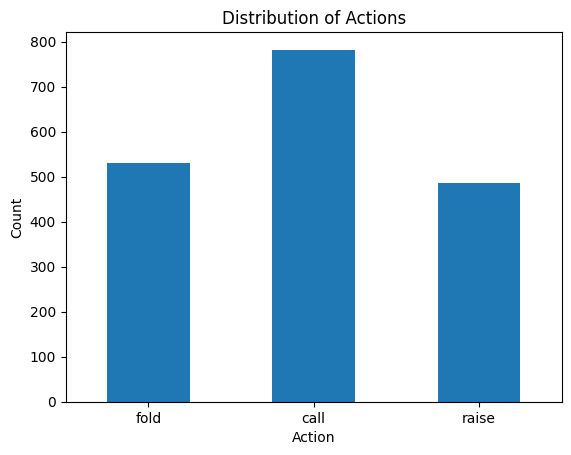

In [ ]:
# get the distribution of actions
counts = df["action"].value_counts().reindex(
    ["fold", "call", "raise"], fill_value=0
)

percentages = (
    df["action"].value_counts(normalize=True) * 100
).reindex(["fold", "call", "raise"], fill_value=0).round(2)

# display the summary table
summary_table = pd.DataFrame({
    "Action": counts.index,
    "Count": counts.values,
    "Percentage": percentages.values
})

display(summary_table)

# plot distribution
df["action"].value_counts().reindex(
    ["fold", "call", "raise"], fill_value=0
).plot(
    kind="bar",
    title="Distribution of Actions",
    rot=0
)

plt.ylabel("Count")
plt.xlabel("Action")
plt.show()



*   Call is the most frequent action
*   Model could predict "call" all the time and be 43% accurate (baseline)



### Relationship between Action and Numerical Input

Do feature value differ depending on the action?

In [ ]:
# compare average of each numerical feature for each action

numeric_features = [
    "hand_strength",
    "pot_odds",
    "stack_to_pot",
    "opponent_aggression",
    "opponent_fold_rate",
    "opponent_bluff_rate"
]

display(
    df.groupby("action")[numeric_features]
      .mean()
      .round(3)
)

,hand_strength,pot_odds,stack_to_pot,opponent_aggression,opponent_fold_rate,opponent_bluff_rate
action,,,,,,
call,0.578,0.272,3.439,0.547,0.503,0.326
fold,0.360,0.318,3.309,0.485,0.519,0.286
raise,0.513,0.259,3.511,0.430,0.562,0.262




* hand strength much lower for fold than call and raise
* pot_odds higher for fold
* stack_to_pot relatively consistent for all actions, higher for raise
* opponent_aggresion much higher for call
* opponent_fold_rate higher for raise
* opponent_bluff_rate much higher for call

Each feature has visible impact on action, thus kept in model training


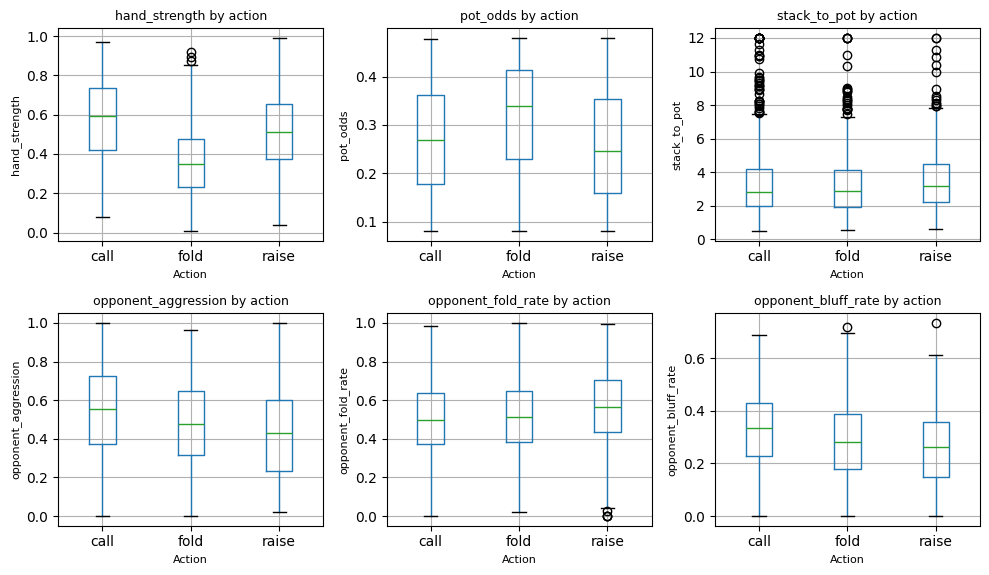

In [ ]:
# box plot for numerical features
num_plots = len(numeric_features)
num_rows = (num_plots + 2) // 3

fig, axes = plt.subplots(num_rows, 3, figsize=(10, 3 * num_rows))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    df.boxplot(column=feature, by="action", ax=axes[i])
    axes[i].set_title(f"{feature} by action", fontsize=9)
    axes[i].set_xlabel("Action", fontsize=8)
    axes[i].set_ylabel(feature, fontsize=8)

plt.suptitle("")
plt.tight_layout()
plt.show()


* middle line represents median
* out of box shows outliers

Each feature has relevant impact on action.

stack_to_pot has an abnormal amount of high outliers, needs more investigation.

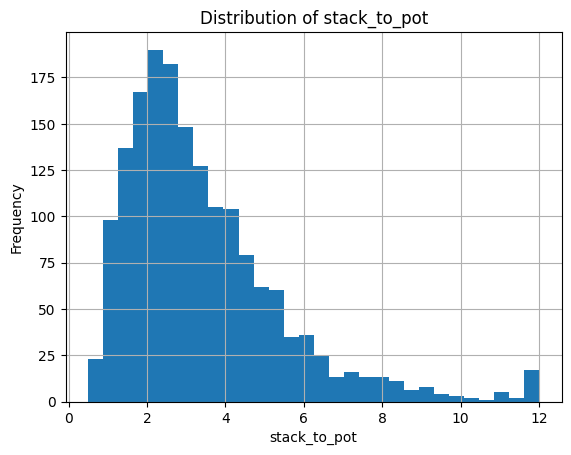

In [ ]:
df["stack_to_pot"].dropna().hist(bins=30)

plt.title("Distribution of stack_to_pot")
plt.xlabel("stack_to_pot")
plt.ylabel("Frequency")
plt.show()

stack_to_pot is highly right-skewed. Should apply log to scale the data into a form the model can train on better while still perserving the order.

### Relationship between Action and Categorical Input

action,fold,call,raise
position,,,
early,0.316,0.467,0.217
late,0.208,0.403,0.388
middle,0.360,0.435,0.205


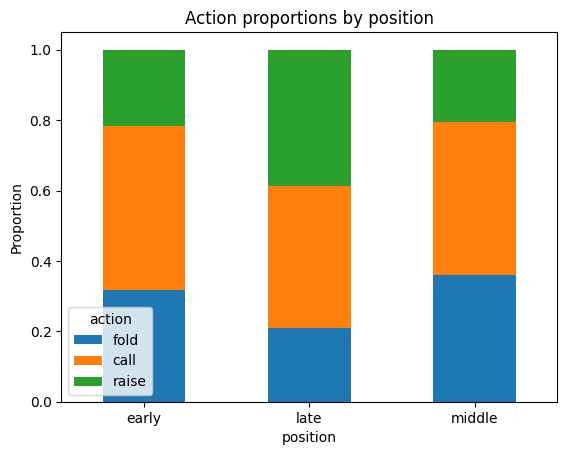

In [ ]:
# relationship between position (categorical feature) and action
position_action = pd.crosstab(
    df["position"],
    df["action"],
    normalize="index"
)

position_action = position_action[["fold", "call", "raise"]]
display(position_action.round(3))

position_action.plot(
    kind="bar",
    stacked=True,
    title="Action proportions by position",
    ylabel="Proportion",
    rot=0
)
plt.show()


For position:

* early games involve more call
* late games involve more raise

Visible impact on action, thus position should be kept in model



In [ ]:
# display examples of recent actions
print("Distinct recent_actions values:",
      df["recent_actions"].nunique())

display(df["recent_actions"].value_counts())


Distinct recent_actions values: 582


,count
recent_actions,
"bet, bet",58
"raise, bet",41
"bet, raise",35
"check, check",34
"check, bet",33
...,...
"call, bet, raise, check",1
"check, bet, call, check",1
"raise, bet, raise, check, raise",1


For recent_actions:

 should be summarized into number of each action in history to be mroe useful for analysis and training.



## 2 · Build

Build a model that outputs a probability distribution over **fold, call, raise**.
Choose what to use from the inputs and how to represent it. Briefly justify your choices.

For the small checks and probes below, assign `predict_probabilities` to a function
that accepts a DataFrame of input rows (without `action`) and returns an `(n, 3)`
numeric array, with columns in `ACTIONS` order. The function should include whatever
preparation your fitted model needs. You may organize your code however you like.

### Data Cleaning and Denoising

Dropped decision_id

In [ ]:
df = df.drop(columns=['decision_id'])

Scale stack_to_pot with log

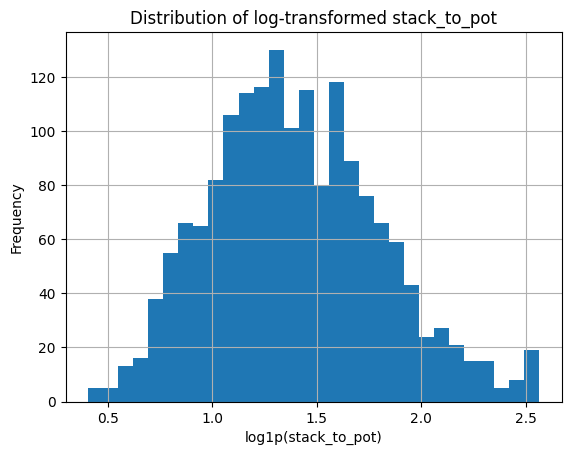

In [ ]:
df["stack_to_pot_log"] = np.log1p(df["stack_to_pot"])
df["stack_to_pot_log"].hist(bins=30)
df = df.drop(columns=["stack_to_pot"])

plt.title("Distribution of log-transformed stack_to_pot")
plt.xlabel("log1p(stack_to_pot)")
plt.ylabel("Frequency")
plt.show()

Summarize recent_action into more usefull rows

In [ ]:
history = df["recent_actions"].fillna("")

actions = history.apply(
    lambda x: [
        action.strip().lower()
        for action in x.split(",")
        if action.strip()
    ]
)

df["recent_check_count"] = actions.apply(lambda x: x.count("check"))
df["recent_call_count"] = actions.apply(lambda x: x.count("call"))
df["recent_bet_count"] = actions.apply(lambda x: x.count("bet"))
df["recent_raise_count"] = actions.apply(lambda x: x.count("raise"))
df["recent_action_count"] = actions.apply(len)

df["last_recent_action"] = actions.apply(
    lambda x: x[-1] if x else "none"
)

df["recent_history_missing"] = (
    df["recent_actions"].isna().astype(int)
)

df = df.drop(columns=["recent_actions"])

Prepare and Split Data

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["action", "decision_id"], errors="ignore")
y = df["action"]

# 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1440, 14)
Testing set: (360, 14)




Use KNN to fill missing values
* Scale data first so KNN distances are more balanced
* Check at the end if data has all been filled



In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Fit scaler on training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train[numeric_features]
)

# Use KNN imputation
imputer = KNNImputer(n_neighbors=5)

X_train_imputed = imputer.fit_transform(X_train_scaled)

# Transform test data using the training scaler and imputer
X_test_scaled = scaler.transform(X_test[numeric_features])
X_test_imputed = imputer.transform(X_test_scaled)

# Restore values to original scales
X_train[numeric_features] = scaler.inverse_transform(X_train_imputed)
X_test[numeric_features] = scaler.inverse_transform(X_test_imputed)

# Check remaining missing values
print("Missing values in training set:", X_train.isna().sum().sum())
print("Missing values in testing set:", X_test.isna().sum().sum())

Missing values in training set: 0
Missing values in testing set: 0


Final Review of Clean Data Set

In [ ]:
display(df.head())
display(df.describe())
display(df.dtypes)

,hand_strength,pot_odds,position,opponent_aggression,opponent_fold_rate,opponent_bluff_rate,action,stack_to_pot_log,recent_check_count,recent_call_count,recent_bet_count,recent_raise_count,recent_action_count,last_recent_action,recent_history_missing
0,0.426436,0.164588,middle,0.442266,0.434870,0.338847,call,0.808578,2,1,2,0,5,check,0
1,0.526809,0.385995,late,0.196157,0.435389,0.311702,call,NaN,0,1,2,0,3,bet,0
2,0.633813,0.374906,early,0.562006,0.349800,0.424215,call,1.429389,0,0,0,0,0,none,1
3,0.516807,0.118063,early,0.532084,0.360803,0.069099,call,1.430250,0,2,1,1,4,bet,0
4,0.676931,0.317998,late,0.572541,0.576514,NaN,call,0.964776,1,0,0,1,2,check,0


,hand_strength,pot_odds,opponent_aggression,opponent_fold_rate,opponent_bluff_rate,stack_to_pot_log,recent_check_count,recent_call_count,recent_bet_count,recent_raise_count,recent_action_count,recent_history_missing
count,1696.000000,1800.000000,1678.000000,1699.000000,1675.000000,1692.000000,1800.000000,1800.000000,1800.00000,1800.000000,1800.000000,1800.000000
mean,0.496616,0.282250,0.497006,0.523699,0.296985,1.398259,0.841667,0.600556,1.17500,0.688333,3.305556,0.055556
std,0.214708,0.115210,0.231308,0.196595,0.144808,0.409034,1.033587,0.765356,1.06066,0.820849,1.356012,0.229125
min,0.007647,0.080437,0.000000,0.000000,0.000000,0.405465,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,0.333338,0.183598,0.316578,0.391987,0.187699,1.107591,0.000000,0.000000,0.00000,0.000000,2.000000,0.000000
50%,0.491890,0.282790,0.502411,0.523781,0.294459,1.363858,1.000000,0.000000,1.00000,0.000000,3.000000,0.000000
75%,0.662507,0.379487,0.678627,0.657727,0.400925,1.663306,1.000000,1.000000,2.00000,1.000000,4.000000,0.000000
max,0.990138,0.479991,1.000000,1.000000,0.733413,2.564949,5.000000,4.000000,5.00000,5.000000,5.000000,1.000000


,0
hand_strength,float64
pot_odds,float64
position,object
opponent_aggression,float64
opponent_fold_rate,float64
opponent_bluff_rate,float64
action,object
stack_to_pot_log,float64
recent_check_count,int64
recent_call_count,int64


### Model Training and Building

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

# identify numeric and categorical columns
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

# convert categorical features into numbers
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# create complete model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['hand_strength', 'pot_odds',
                                                   'opponent_aggression',
                                                   'opponent_fold_rate',
                                                   'opponent_bluff_rate',
                                                   'stack_to_pot_log',
                                                   'recent_check_count',
                                                   'recent_call_count',
                                                   'recent_bet_count',
                                                   'recent_raise_count',
                                                   'recent_action_count',
                                                   'recent_history_missing']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['position',
                                                   'last_recent_action'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

In [ ]:
# replacing predict_probabilities function
def predict_probabilities(X):
    probabilities = model.predict_proba(X)

    classes = list(model.named_steps["classifier"].classes_)
    order = [classes.index(action) for action in ["fold", "call", "raise"]]

    return probabilities[:, order]


**Approach and assumptions:**

Multinomial logistic regression (MLR) was chosen because the target variable has three possible outcomes — fold, call, and raise — and MLR can estimate the probability of each action. The model was trained using all the features provided with some altered in different forms for training purposes. Specifically, numeric features were scaled and missing values were handled using KNN imputation, while categorical features were imputed and one-hot encoded. We assumed that KNN imputation would not alter the data set significantly and skew the prediction results.

In [ ]:
# Optional interface check: this checks format, not model quality.
def checked_probabilities(rows):
    p = np.asarray(predict_probabilities(rows), dtype=float)
    assert p.shape == (len(rows), len(ACTIONS)), "Expected one row and three probabilities per input."
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all(), "Probabilities must be finite and in [0, 1]."
    assert np.allclose(p.sum(axis=1), 1, atol=1e-6), "Each row must sum to 1."
    return pd.DataFrame(p, columns=ACTIONS, index=rows.index)

if predict_probabilities is None:
    print("Interface check pending: add your model in section 2.")
else:
    display(checked_probabilities(df.drop(columns="action").head(3)))

,fold,call,raise
0,0.342376,0.354043,0.303582
1,0.210215,0.237387,0.552398
2,0.293388,0.476156,0.230457


## 3 · Evaluate

Decide how to evaluate your model. Choose metrics you think are appropriate and explain
what they tell you about its probabilities and decisions. Show your results and explain
which conclusions you trust, which you do not, and why.

Test Accuracy: 0.5083

Classification Report:
              precision    recall  f1-score   support

        fold       0.52      0.61      0.56       106
        call       0.60      0.47      0.53       156
       raise       0.40      0.45      0.42        98

    accuracy                           0.51       360
   macro avg       0.50      0.51      0.50       360
weighted avg       0.52      0.51      0.51       360



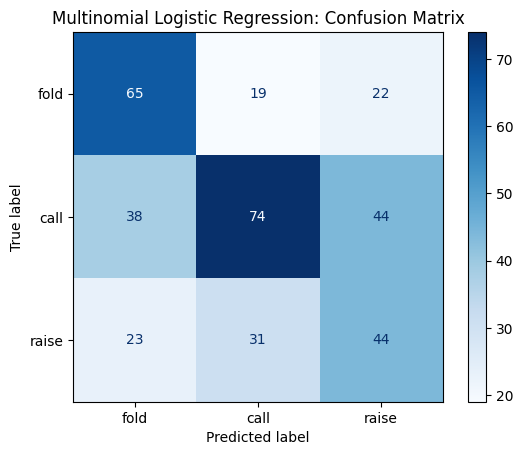

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# predict actions on the test set
y_pred = model.predict(X_test)

# 1. Overall Accuracy
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))

# 2. Precision, Recall, and F1-score for each action
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["fold", "call", "raise"],
    zero_division=0
))

# 3. Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["fold", "call", "raise"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["fold", "call", "raise"]
)
disp.plot(cmap="Blues")
plt.title("Multinomial Logistic Regression: Confusion Matrix")
plt.show()

**Evidence and interpretation:**

The following 5 types of metrics were used in the project:

**Accuracy:** Measures the proportion of poker decisions the model predicts correctly. It gives an overall measure of performance, but can hide poor performance on individual actions.

**Precision:** Measures how often the model's predictions for each action are correct. For example, high precision for raise means that when the model predicts a raise, it is often correct.

**Recall:** Measures how many actual instances of each action the model correctly identifies. This shows whether the model misses many folds, calls, or raises.

**F1-score:** Balances precision and recall, making it useful for comparing performance across the three actions.

**Confusion matrix:** Shows which actions the model confuses with one another, such as predicting call when the actual action was raise.

The multinomial logistic regression model achieved a test accuracy of 50.83%, indicating moderate predictive performance. This is higher than the baseline, which is 43.44% for guessing solely the most common action, calls. The model performed best at identifying folds, with an F1-score of 0.56, followed by calls at 0.53, while raises were the most difficult to predict, with an F1-score of 0.42. The confusion matrix shows that the model frequently misclassified calls and raises as other actions, suggesting difficulty distinguishing between these decisions. Overall, the model learns some patterns in poker actions, but its performance could be improved, particularly in predicting raises.

## 4 · Probe behavior

Investigate how your model behaves when you change one or two features while keeping
the others fixed. The rows below are starting points; choose your own comparisons.
Show the probabilities, describe what surprised you, and explain a limitation of your probe.

In [ ]:
#Case 1: hand strength increased from 0.30 to 0.80 for low opponent_fold_rate (0.2)
probe_rows = pd.DataFrame([
    {
        "hand_strength": 0.30,
        "pot_odds": 0.30,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "late",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.20,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    },
    {
        "hand_strength": 0.80,
        "pot_odds": 0.30,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "late",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.20,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    }
])

if predict_probabilities is None:
    display(probe_rows)
else:
    display(pd.concat([probe_rows, checked_probabilities(probe_rows)], axis=1))

# Case 2: hand strength increased from 0.30 to 0.80 for high opponent_fold_rate (0.85)
probe_rows = pd.DataFrame([
    {
        "hand_strength": 0.30,
        "pot_odds": 0.30,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "late",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.85,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    },
    {
        "hand_strength": 0.80,
        "pot_odds": 0.30,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "late",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.85,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    }
])

if predict_probabilities is None:
    display(probe_rows)
else:
    display(pd.concat([probe_rows, checked_probabilities(probe_rows)], axis=1))

#Case 3: pot odds increased from 0.30 to 0.80 for low hand_strength (0.3)
probe_rows = pd.DataFrame([
    {
        "hand_strength": 0.30,
        "pot_odds": 0.30,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "late",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.20,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    },
    {
        "hand_strength": 0.30,
        "pot_odds": 0.80,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "late",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.20,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    }
])

if predict_probabilities is None:
    display(probe_rows)
else:
    display(pd.concat([probe_rows, checked_probabilities(probe_rows)], axis=1))

# Case 4: pot odds increased from 0.30 to 0.80 for low hand_strength (0.8)
probe_rows = pd.DataFrame([
    {
        "hand_strength": 0.80,
        "pot_odds": 0.30,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "late",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.85,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    },
    {
        "hand_strength": 0.80,
        "pot_odds": 0.80,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "late",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.85,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    }
])

if predict_probabilities is None:
    display(probe_rows)
else:
    display(pd.concat([probe_rows, checked_probabilities(probe_rows)], axis=1))

# Case 5: early vs late positions
probe_rows = pd.DataFrame([
    {
        "hand_strength": 0.30,
        "pot_odds": 0.30,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "early",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.85,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    },
    {
        "hand_strength": 0.30,
        "pot_odds": 0.30,
        "stack_to_pot_log": __import__("numpy").log1p(3.0),
        "position": "late",
        "opponent_aggression": 0.45,
        "opponent_fold_rate": 0.85,
        "opponent_bluff_rate": 0.25,
        "recent_check_count": 1,
        "recent_call_count": 1,
        "recent_bet_count": 1,
        "recent_raise_count": 0,
        "recent_action_count": 3,
        "last_recent_action": "bet",
        "recent_history_missing": 0
    }
])

if predict_probabilities is None:
    display(probe_rows)
else:
    display(pd.concat([probe_rows, checked_probabilities(probe_rows)], axis=1))



,hand_strength,pot_odds,stack_to_pot_log,position,opponent_aggression,opponent_fold_rate,opponent_bluff_rate,recent_check_count,recent_call_count,recent_bet_count,recent_raise_count,recent_action_count,last_recent_action,recent_history_missing,fold,call,raise
0,0.3,0.3,1.386294,late,0.45,0.2,0.25,1,1,1,0,3,bet,0,0.370399,0.204624,0.424977
1,0.8,0.3,1.386294,late,0.45,0.2,0.25,1,1,1,0,3,bet,0,0.061812,0.498427,0.439761


,hand_strength,pot_odds,stack_to_pot_log,position,opponent_aggression,opponent_fold_rate,opponent_bluff_rate,recent_check_count,recent_call_count,recent_bet_count,recent_raise_count,recent_action_count,last_recent_action,recent_history_missing,fold,call,raise
0,0.3,0.3,1.386294,late,0.45,0.85,0.25,1,1,1,0,3,bet,0,0.255596,0.147032,0.597372
1,0.8,0.3,1.386294,late,0.45,0.85,0.25,1,1,1,0,3,bet,0,0.041861,0.351482,0.606657


,hand_strength,pot_odds,stack_to_pot_log,position,opponent_aggression,opponent_fold_rate,opponent_bluff_rate,recent_check_count,recent_call_count,recent_bet_count,recent_raise_count,recent_action_count,last_recent_action,recent_history_missing,fold,call,raise
0,0.3,0.3,1.386294,late,0.45,0.2,0.25,1,1,1,0,3,bet,0,0.370399,0.204624,0.424977
1,0.3,0.8,1.386294,late,0.45,0.2,0.25,1,1,1,0,3,bet,0,0.819505,0.076356,0.104140


,hand_strength,pot_odds,stack_to_pot_log,position,opponent_aggression,opponent_fold_rate,opponent_bluff_rate,recent_check_count,recent_call_count,recent_bet_count,recent_raise_count,recent_action_count,last_recent_action,recent_history_missing,fold,call,raise
0,0.8,0.3,1.386294,late,0.45,0.85,0.25,1,1,1,0,3,bet,0,0.041861,0.351482,0.606657
1,0.8,0.8,1.386294,late,0.45,0.85,0.25,1,1,1,0,3,bet,0,0.248679,0.352160,0.399160


,hand_strength,pot_odds,stack_to_pot_log,position,opponent_aggression,opponent_fold_rate,opponent_bluff_rate,recent_check_count,recent_call_count,recent_bet_count,recent_raise_count,recent_action_count,last_recent_action,recent_history_missing,fold,call,raise
0,0.3,0.3,1.386294,early,0.45,0.85,0.25,1,1,1,0,3,bet,0,0.501137,0.181071,0.317792
1,0.3,0.3,1.386294,late,0.45,0.85,0.25,1,1,1,0,3,bet,0,0.255596,0.147032,0.597372


**Probe findings:**

Prioritized over cases that should trigger a change raise, since the model has shown to be bad at identifying raises. Also cases that might cause confusion to the model.

Case 1 (tests how model responds to hand_strength; significant increase in strength should trigger higher raise):
* fold: 37.04% -> 6.18%
* call: 20.46% -> 49.84%
* raise: 42.50% -> 43.98%
* Surprised that probability of raising didn't change much at all, only increasing by 1%

Case 2 (when compared with Case 1, tests whether opponent fold rate impacts model's response to hand strengths; higher fold rate should trigger more raise when hand strength increase):
* fold: 25.56% -> 4.19%
* call: 14.70% -> 35.15%
* raise: 59.73% -> 60.67%
* Surprised that raise% again only increased by less than 1%

Case 3 (tests how model responds to pot odds; call% should decrease as pot odds increase):
* fold: 37.04% -> 81.95%
* call: 20.46% -> 7.64%
* raise: 42.50% -> 10.41%
* Fold more than doubled, raise decreased by 75%, and call decraesed 60%; model seems very sensitive to pot odds when hand strength is low, good behaviour.

Case 4 (when compared with Case 3, tests whether model distinguishes between cost of calling and strength of a hand):
* fold: 4.19% -> 24.87%
* call: 35.15% -> 35.22%
* raise: 60.67% -> 39.92%
* Model seems a lot less sensitive to pot odds when hand is good, good behaviour.

Case 5 (tests model's response to different stages of game):
* fold: 50.11% -> 25.56%
* call: 18.12% -> 14.70%
* raise: 31.78% -> 59.74%
* Surprised that

Overall, probe revealed that model has trouble handlign situations where raise should be changing more drastically. Some limitations include:

* probes test only a few scenarios and may not represent all poker situations

* changing features individually may overlook interactions between features

* model learns recorded player behavior, which may not reflect optimal poker strategy, meaning some it's hard to necesaribly say whether a prediction is reasonable or not

## 5 · Improve one aspect

Improve the system in one way you think is valuable. Define what “improve” means for
your choice, then provide evidence. A well-explained unsuccessful experiment is useful too.
Keep this small enough to finish within the time budget.


CLASS WEIGHTS: balanced

Test Accuracy: 0.508

Classification Report:
              precision    recall  f1-score   support

        fold       0.52      0.61      0.56       106
        call       0.60      0.47      0.53       156
       raise       0.40      0.45      0.42        98

    accuracy                           0.51       360
   macro avg       0.50      0.51      0.50       360
weighted avg       0.52      0.51      0.51       360

Confusion Matrix (rows = actual, columns = predicted):
[[65 19 22]
 [38 74 44]
 [23 31 44]]


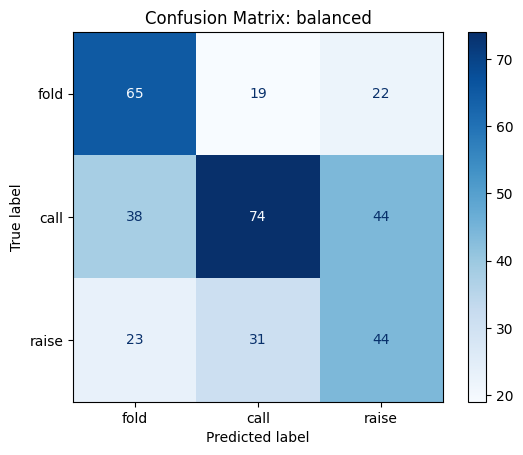


CLASS WEIGHTS: {'fold': 1, 'call': 1, 'raise': 1.25}

Test Accuracy: 0.542

Classification Report:
              precision    recall  f1-score   support

        fold       0.57      0.58      0.58       106
        call       0.58      0.62      0.60       156
       raise       0.43      0.38      0.40        98

    accuracy                           0.54       360
   macro avg       0.53      0.53      0.53       360
weighted avg       0.54      0.54      0.54       360

Confusion Matrix (rows = actual, columns = predicted):
[[62 26 18]
 [28 96 32]
 [18 43 37]]


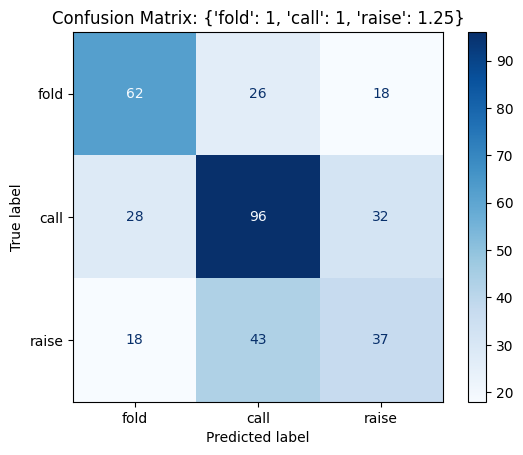


CLASS WEIGHTS: {'fold': 1.5, 'call': 1.5, 'raise': 2.0}

Test Accuracy: 0.522

Classification Report:
              precision    recall  f1-score   support

        fold       0.55      0.54      0.55       106
        call       0.59      0.59      0.59       156
       raise       0.39      0.40      0.39        98

    accuracy                           0.52       360
   macro avg       0.51      0.51      0.51       360
weighted avg       0.52      0.52      0.52       360

Confusion Matrix (rows = actual, columns = predicted):
[[57 24 25]
 [27 92 37]
 [19 40 39]]


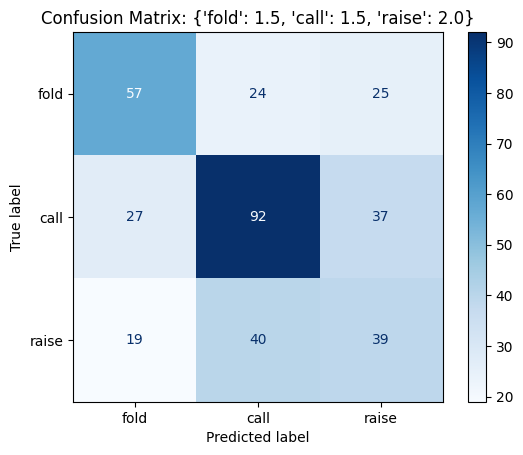

In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

weights_to_test = [
    "balanced",
    {"fold": 1, "call": 1, "raise": 1.25},
    {"fold": 1.5, "call": 1.5, "raise": 2.0}
]

for weights in weights_to_test:
    print("\n" + "=" * 55)
    print(f"CLASS WEIGHTS: {weights}")
    print("=" * 55)

    # Train a copy of your original model
    test_model = clone(model)
    test_model.set_params(classifier__class_weight=weights)
    test_model.fit(X_train, y_train)

    # Make predictions
    predictions = test_model.predict(X_test)

    # Print accuracy
    print(f"\nTest Accuracy: {accuracy_score(y_test, predictions):.3f}")

    # Print precision, recall, and F1 for every class
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        labels=["fold", "call", "raise"],
        zero_division=0
    ))

    # Print confusion matrix
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["fold", "call", "raise"]
    )

    print("Confusion Matrix (rows = actual, columns = predicted):")
    print(cm)

    # display confusion matrix as a plot
    displ = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["fold", "call", "raise"]
    )
    displ.plot(cmap="Blues")
    plt.title(f"Confusion Matrix: {weights}")
    plt.show()




**Change, evidence, and tradeoffs:**

I improved the model by changing the class weights to give more importance to predicting raise. I tested different settings, including "balanced" (original), "fold: 1, call: 1, raise: 1.25", and "fold: 1.5, call: 1.5, raise: 2.0", while keeping the same logistic regression model and preprocessing. The best result came from "fold: 1, call: 1, raise: 1.25", which increased overall test accuracy from 50.8% to 54.2%. It also increased the precision and recal score for all three action predictions, and the F1 score for fold and call. However, the tradeoff is that this setting actually reduced the raise F1 score from 0.42 to 0.40, correctly identifying only 37 actual raises compared with 44 in the original model. Nonetheless, I find that the increase in other parameters overcomes the insufficiency in that one area.

## 6 · Final reflection: working with AI

Keep this brief and specific. Short prompt excerpts or descriptions are enough; a full chat log is unnecessary.

1. **Tools and direction:** Which AI tools did you use, and what did you ask them to do?
2. **Accepted suggestion:** Describe one suggestion you accepted, why, and how you checked it.
3. **Rejected or modified suggestion:** Describe one suggestion you rejected or changed and your reasoning.
4. **Your own discovery:** What did your investigation reveal that the agent did not initially point out? How did it change your approach?
5. **Looking back:** How long did you spend, what is the main limitation, and what would you try next?

If there was no suggestion to reject or no independent discovery, say so honestly and
describe how you challenged an AI assumption or attempted your own investigation.

**Your reflection:**

I used ChatGPT and Claude to finish this project. Since I have limited experience in building models that take multiple input features, I had AI explain to me a few strategies for this poker project (Multinomial Logistic Regression Model, Decision tree, Gradient Boosting, etc) and suggest the best one based on the tasks given. I also asked for suggestions on how to denoise my data (which features to keep, which to remove, why, etc), and let it write some code for repepetive chunks and in areas I'm not familiar with.

A suggestion I took is the use Multinomial Logistic Regression. I double checked through some online research. The specific reasoning I put in the previous section. A suggestion I rejected is to impute the missing data by using median and mean of other data in that row. I think that will result in too much limitations on the std and end up skewing the resulting predictions. Something I discovered on my own is that changing the balance and attention to each action helps to improve the overall accuracy and metric scores.

Overall, this took me a bit long, a little over 3 hours, because there are a lot of areas here that I'm not familiar with, and I also wanted to make my solution detailed. The main limitation is having to learn a lot of stuff as I go. If I had more time, I can try making this project with another approach, like using gradient boosting to see if that changes the predictions.